# Models 2 and 3 — predicting my decision and my partner's decision

Every row is one date. The features describe **both** people:

| Feature set | Features | Known |
|---|---|---|
| **both profiles** | my sign-up profile + the partner's sign-up profile (joined by `pid`, prefixed `p_`) | before the date |
| **profiles + ratings** | both profiles + both scorecards of this date: `attr`, `sinc`, `intel`, `fun`, `amb`, `shar`, `like`, `prob`, `met` and the same with `_o` | after the date |

Two targets:
* **Model 2:** `dec` — my decision about the partner;
* **Model 3:** `dec_o` — the partner's decision about me.

The scorecards are filled in at the same moment as the decision, so a model with ratings answers
*"given the scorecards, what was decided?"*, not *"will these two people like each other?"*. The
**both profiles** set answers the second question.

Evaluation as in Model 1: leave-one-wave-out cross-validation (21 folds), preprocessing fitted inside every
fold, majority-class baseline, accuracy / F1 / ROC AUC.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd

from speed_dating.data import RESULTS_DIR, load_data
from speed_dating.evaluation import evaluate, plot_per_wave, plot_train_test, test_summary
from speed_dating.features import FEATURE_SETS, build_dataset

df = load_data()
TARGETS = {"dec": "Model 2 — my decision", "dec_o": "Model 3 — partner's decision"}

all_results = {}
for target in TARGETS:
    for feature_set in ["both_profiles", "profiles_and_ratings"]:
        X, y, waves = build_dataset(df, target=target, feature_set=feature_set)
        print(f"{target:5s} {feature_set:22s} {len(X)} dates, {X.shape[1]} features, share of 'yes': {y.mean():.1%}")
        results = evaluate(X, y, waves)
        results.to_csv(RESULTS_DIR / f"model_{target}_{feature_set}.csv", index=False)
        all_results[(target, feature_set)] = results

dec   both_profiles          7886 dates, 76 features, share of 'yes': 42.2%
dec   profiles_and_ratings   5314 dates, 94 features, share of 'yes': 43.8%
dec_o both_profiles          7886 dates, 76 features, share of 'yes': 42.2%
dec_o profiles_and_ratings   5314 dates, 94 features, share of 'yes': 43.8%


## Model 2 — my decision (`dec`)
### Before the date: both profiles

In [2]:
test_summary(all_results[("dec", "both_profiles")])

metric,Accuracy,F1,ROC AUC
model,,,
Majority baseline,0.562 ± 0.059,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.600 ± 0.042,0.487 ± 0.096,0.629 ± 0.071
Gaussian NB,0.537 ± 0.055,0.551 ± 0.078,0.567 ± 0.056
SVM (linear),0.597 ± 0.047,0.480 ± 0.097,0.627 ± 0.069
KNN (k=89),0.584 ± 0.050,0.366 ± 0.095,0.604 ± 0.070
Random Forest,0.582 ± 0.045,0.310 ± 0.102,0.611 ± 0.083


### After the date: profiles + ratings

In [3]:
test_summary(all_results[("dec", "profiles_and_ratings")])

metric,Accuracy,F1,ROC AUC
model,,,
Majority baseline,0.551 ± 0.065,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.764 ± 0.055,0.732 ± 0.075,0.842 ± 0.054
Gaussian NB,0.673 ± 0.051,0.648 ± 0.107,0.733 ± 0.059
SVM (linear),0.769 ± 0.046,0.740 ± 0.067,0.845 ± 0.047
KNN (k=89),0.728 ± 0.057,0.666 ± 0.087,0.808 ± 0.058
Random Forest,0.767 ± 0.046,0.731 ± 0.066,0.844 ± 0.045


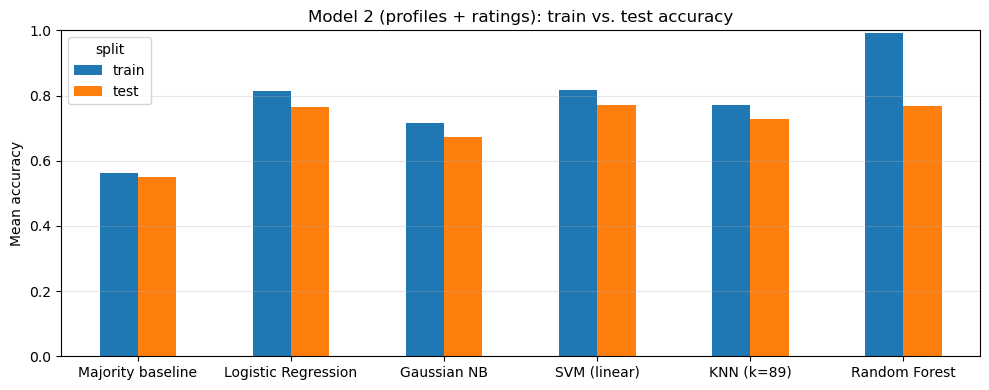

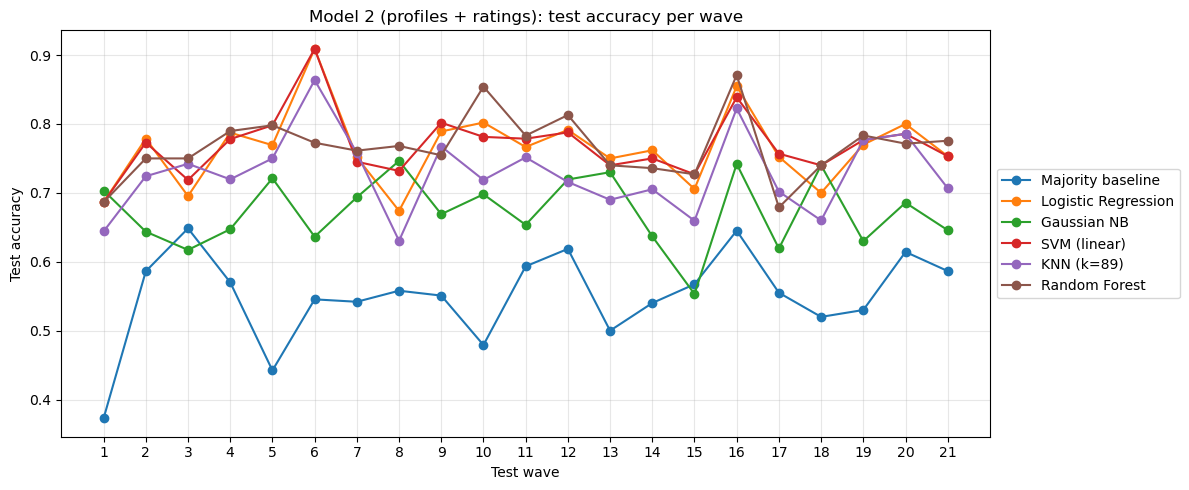

In [4]:
plot_train_test(all_results[("dec", "profiles_and_ratings")], title="Model 2 (profiles + ratings): train vs. test accuracy")
plt.show()
plot_per_wave(all_results[("dec", "profiles_and_ratings")], title="Model 2 (profiles + ratings): test accuracy per wave")
plt.show()

## Model 3 — the partner's decision (`dec_o`)
### Before the date: both profiles

In [5]:
test_summary(all_results[("dec_o", "both_profiles")])

metric,Accuracy,F1,ROC AUC
model,,,
Majority baseline,0.562 ± 0.059,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.600 ± 0.042,0.487 ± 0.096,0.629 ± 0.071
Gaussian NB,0.537 ± 0.055,0.551 ± 0.078,0.567 ± 0.056
SVM (linear),0.597 ± 0.047,0.479 ± 0.097,0.627 ± 0.069
KNN (k=89),0.584 ± 0.050,0.366 ± 0.095,0.604 ± 0.070
Random Forest,0.588 ± 0.050,0.329 ± 0.114,0.622 ± 0.076


### After the date: profiles + ratings

In [6]:
test_summary(all_results[("dec_o", "profiles_and_ratings")])

metric,Accuracy,F1,ROC AUC
model,,,
Majority baseline,0.551 ± 0.065,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.768 ± 0.060,0.737 ± 0.080,0.842 ± 0.054
Gaussian NB,0.674 ± 0.051,0.645 ± 0.108,0.731 ± 0.057
SVM (linear),0.771 ± 0.046,0.742 ± 0.067,0.845 ± 0.047
KNN (k=89),0.727 ± 0.059,0.669 ± 0.087,0.808 ± 0.060
Random Forest,0.765 ± 0.039,0.728 ± 0.066,0.844 ± 0.048


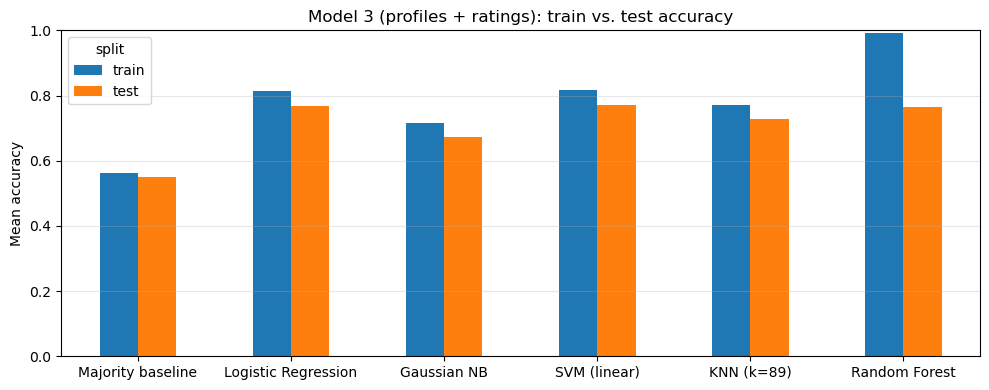

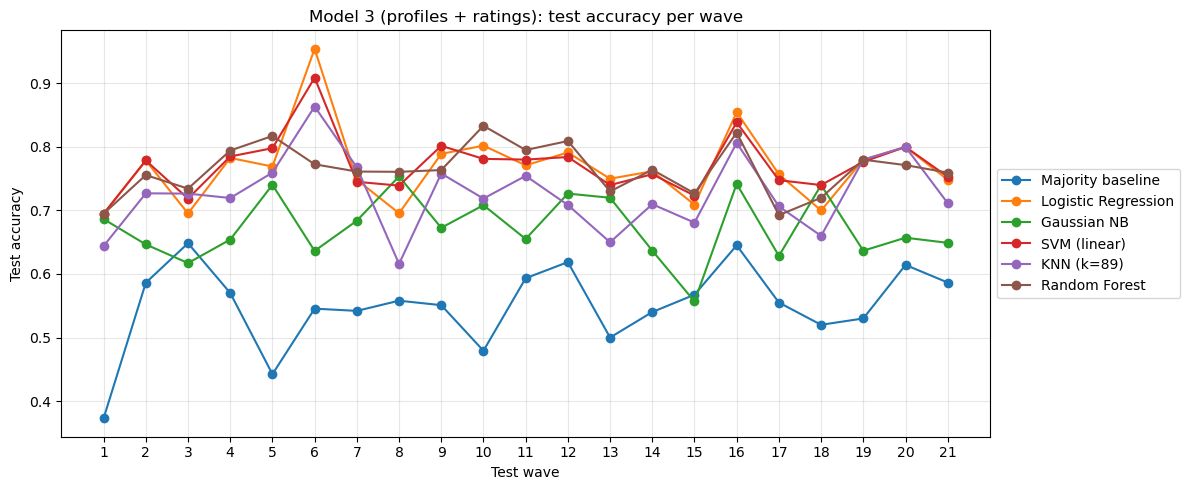

In [7]:
plot_train_test(all_results[("dec_o", "profiles_and_ratings")], title="Model 3 (profiles + ratings): train vs. test accuracy")
plt.show()
plot_per_wave(all_results[("dec_o", "profiles_and_ratings")], title="Model 3 (profiles + ratings): test accuracy per wave")
plt.show()

## What does the model look at?
Coefficients of the logistic regression (profiles + ratings, trained on all waves). Numeric features are
standardized, so their coefficients are comparable: the 15 largest by absolute value are shown.
One-hot columns (race, field, goal, career) are left out — a rare category with a handful of people gets a
large coefficient that says little.

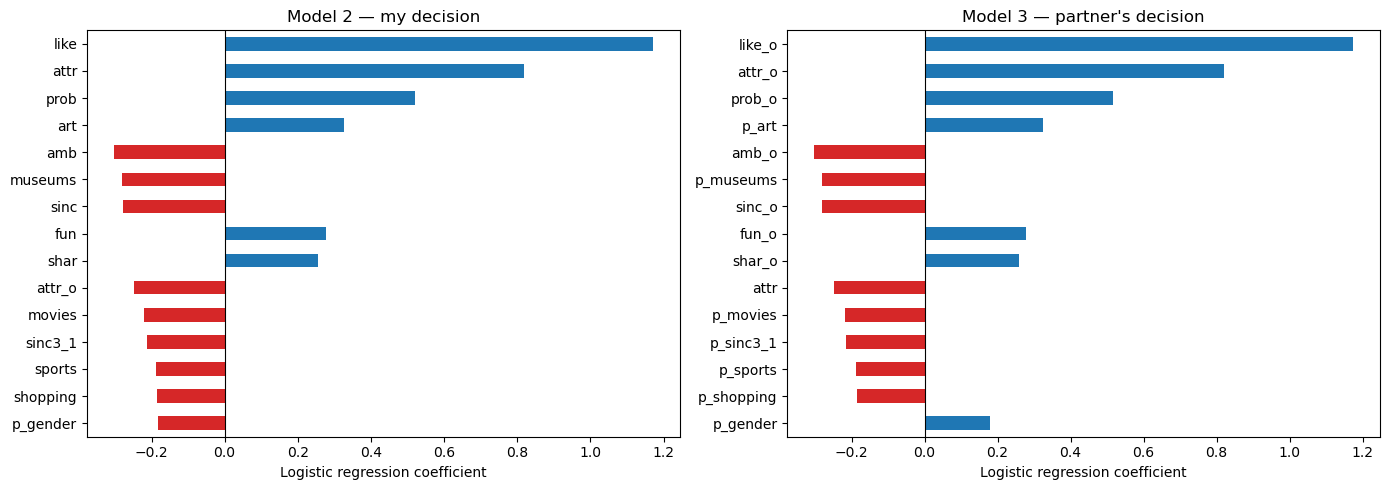

In [8]:
from speed_dating.evaluation import make_models, make_pipeline_for

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (target, title) in zip(axes, TARGETS.items()):
    X, y, _ = build_dataset(df, target=target, feature_set="profiles_and_ratings")
    pipe = make_pipeline_for(X, make_models()["Logistic Regression"]).fit(X, y)
    names = pipe[0].get_feature_names_out()
    coef = pd.Series(pipe[-1].coef_[0], index=names)
    coef = coef[coef.index.str.startswith("numeric__")].rename(lambda n: n.split("__", 1)[1])
    top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15])[::-1]
    top.plot.barh(ax=ax, color=["C3" if v < 0 else "C0" for v in top], title=title)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Logistic regression coefficient")
plt.tight_layout()
plt.show()

## Conclusions

* **Before the date** (both profiles) the decision is still hard to predict: 60% accuracy against 56% for
  the baseline, ROC AUC 0.63. Adding the partner's profile helps only a little compared with Model 1.
* **After the date** (profiles + both scorecards) the linear models and the random forest reach
  **77% accuracy, F1 0.74, ROC AUC 0.84**, 21 points above the baseline. Logistic regression, linear SVM
  and random forest are equally good on the test waves — the signal is mostly linear. The linear models
  have a small train–test gap (81% → 77%); the random forest fits the training data almost perfectly (99%)
  without being better on new waves.
* The decision is driven by **how much I liked the partner** (`like`), **attractiveness** (`attr`) and
  **whether I think the partner liked me** (`prob`). With these fixed, higher sincerity and ambition
  ratings even slightly lower the chance of a "yes" — compare with section 3 of the EDA, where people
  *say* sincerity and intelligence matter as much as looks.
* **Models 2 and 3 give practically the same results — by construction.** Every date is stored twice,
  once from each side, and `dec` on one row equals `dec_o` on the mirrored row (checked: 8368 of 8378 rows
  have a mirror, all consistent). With symmetric features, predicting the partner's decision is the same
  task on the mirrored rows. Both rows of a date belong to the same wave, so the mirroring does not leak
  between training and test waves.